# 🏗️ Hypothese 3: Spart man pro qm mit durchschnittlicher Bauqualität?
**EDA King County House Sales** · Kunde: **Thomas Hansen** · einfache Version

| # | Schritt (nach `02_workflow`) |
|---|---|
| 1 | Kunde, Forschungsfrage & Hypothese |
| 2 | Daten verstehen |
| 3 | Daten bereinigen & Gruppen bilden |
| 4 | Daten erkunden |
| 5 | Zusammenhänge |
| 6 | Hypothese prüfen: Gesamtmarkt |
| 7 | Folgefrage: fairer Vergleich (gleiche PLZ, gleiche Größe) |
| 8 | Fancy Visual: Preisvergleich je Postleitzahl |
| 9 | Erkenntnisse & Empfehlungen |

---
## 1 · Kunde, Forschungsfrage & Hypothese
**Thomas Hansen** (Käufer): 5 Kinder, wenig Geld, braucht vor allem **Fläche**. Seine Frage: *Spare ich pro qm spürbar, wenn ich auf gehobene Ausstattung verzichte?*

| Frage | Hypothese | Indikatoren |
|---|---|---|
| Beeinflusst die Bauqualität den Quadratmeterpreis? | Häuser mit **durchschnittlicher Bauqualität** sind im **Median pro qm deutlich günstiger** als Häuser mit **gehobener Ausführung**. | `grade`, `price`, `qm_living` (+ `zipcode` für den fairen Vergleich) |

**Annahmen** (laut King County Assessor Glossar für `grade`):
* **Durchschnittlich** = **Grade 7** (*„Average grade of construction and design“*).
* **Gehoben** = **Grade 9–10** (*„Better architectural design …“*, *„high quality features“*). Grade 8 ist eine Zwischenstufe, Grade 11–13 ist Luxus.
* **Pro qm** = `price / qm_living`.
* **Deutlich** = mindestens **15 %** günstiger. Begründung: Die Baukosten zwischen „mittlerer“ und „gehobener“ Ausstattung unterscheiden sich laut deutschen Normalherstellungskosten (NHK 2010) um rund 17 %. Wir runden vorsichtig ab.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False  # "$" ist hier Währung, keine Formel
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
Path("output").mkdir(exist_ok=True)

---
## 2 · Daten verstehen

In [12]:
# Die Rohdaten wurden in 03_fetching_the_data_eda per SQL (JOIN der beiden Tabellen im Schema eda) geholt
# und in 04_eda.ipynb bereinigt (33 → 3 Schlafzimmer, yr_renovated / 10, fehlende Werte, sqft → qm).
df = pd.read_csv("data/eda_tk_cleaned.csv", parse_dates=["date"])
print("Zeilen, Spalten:", df.shape)
print("Zeitraum:", df["date"].min().date(), "bis", df["date"].max().date())
df.head()

Zeilen, Spalten: (21597, 26)
Zeitraum: 2014-05-02 bis 2015-05-27


,sale_id,house_id,date,price,bedrooms,bathrooms,qm_living,qm_lot,floors,waterfront,...,yr_renovated,zipcode,lat,long,qm_living15,qm_lot15,yr_renovated_unbekannt,keller_typ,preis_pro_qm_wohnflaeche,preis_pro_qm_grundstueck
0,1,7129300520,2014-10-13,"221,900.00",3,1.00,109.63,524.90,1.00,0,...,0,98178,47.51,-122.26,124.49,524.90,False,Kein Keller (0 qm),"2,024.08",422.75
1,2,6414100192,2014-12-09,"538,000.00",3,2.25,238.76,672.80,2.00,0,...,1991,98125,47.72,-122.32,157.01,709.69,False,Nutzbarer Keller (>= 5 qm),"2,253.31",799.64
2,3,5631500400,2015-02-25,"180,000.00",2,1.00,71.54,929.03,1.00,0,...,0,98028,47.74,-122.23,252.70,748.98,True,Kein Keller (0 qm),"2,516.07",193.75
3,4,2487200875,2014-12-09,"604,000.00",4,3.00,182.09,464.52,1.00,0,...,0,98136,47.52,-122.39,126.35,464.52,False,Nutzbarer Keller (>= 5 qm),"3,317.04","1,300.27"
4,5,1954400510,2015-02-18,"510,000.00",3,2.00,156.08,750.66,1.00,0,...,0,98074,47.62,-122.05,167.23,697.05,False,Kein Keller (0 qm),"3,267.56",679.40


In [13]:
spalten = ["price", "qm_living", "preis_pro_qm_wohnflaeche", "grade", "yr_built", "zipcode"]
print(df[spalten].dtypes, "\n")
print("Fehlende Werte je Spalte:\n", df[spalten].isna().sum())
print("\nHäufigkeit grade:\n", df["grade"].value_counts().sort_index())
df[spalten].describe()

price                       float64
qm_living                   float64
preis_pro_qm_wohnflaeche    float64
grade                         int64
yr_built                      int64
zipcode                       int64
dtype: object 

Fehlende Werte je Spalte:
 price                       0
qm_living                   0
preis_pro_qm_wohnflaeche    0
grade                       0
yr_built                    0
zipcode                     0
dtype: int64

Häufigkeit grade:
 grade
3        1
4       27
5      242
6     2038
7     8974
8     6065
9     2615
10    1134
11     399
12      89
13      13
Name: count, dtype: int64


,price,qm_living,preis_pro_qm_wohnflaeche,grade,yr_built,zipcode
count,"21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00"
mean,"540,296.57",193.27,"2,843.22",7.66,"1,971.00","98,077.95"
std,"367,368.14",85.29,"1,184.03",1.17,29.38,53.51
min,"78,000.00",34.37,942.76,3.00,"1,900.00","98,001.00"
25%,"322,000.00",132.85,"1,962.18",7.00,"1,951.00","98,033.00"
50%,"450,000.00",177.44,"2,633.27",7.00,"1,975.00","98,065.00"
75%,"645,000.00",236.90,"3,426.57",8.00,"1,997.00","98,118.00"
max,"7,700,000.00","1,257.91","8,719.85",13.00,"2,015.00","98,199.00"


**Was sehen wir?**
* Keine fehlenden Werte.
* `grade` ist **kategorial (geordnet)** von 3 bis 13. Grade 7 ist mit ~9.000 Verkäufen die häufigste Stufe, gefolgt von Grade 8. Grade 9–10 kommen zusammen auf ~3.700.
* **Stetig:** `price`, `qm_living`, `preis_pro_qm_wohnflaeche`, `yr_built`.

---
## 3 · Daten bereinigen & Gruppen bilden
Die Bereinigung ist in `04_eda.ipynb` passiert. Hier bilden wir nur die zwei Vergleichsgruppen und prüfen die Ausreißer.

gruppe
durchschnittlich (7)    8974
gehoben (9–10)          3749
Name: count, dtype: int64
Nicht im Vergleich (Grade 3–6, 8, 11–13): 8,874 Verkäufe, nicht gelöscht, nur nicht verglichen


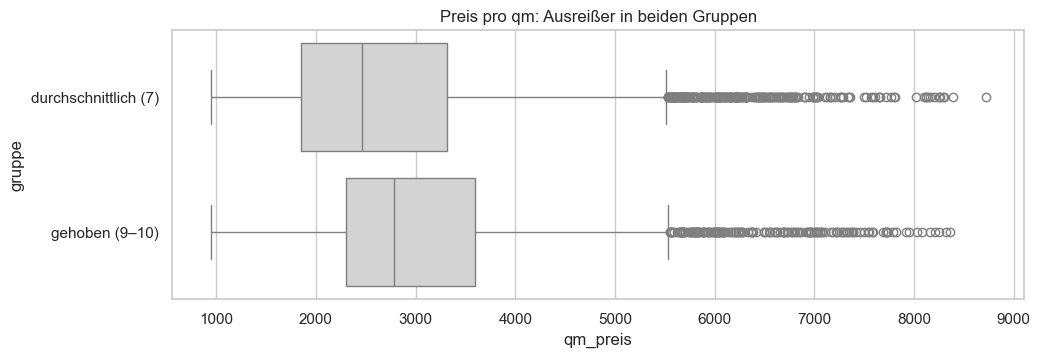

Verworfene Zeilen: 0 (Ausreißer sind echte Verkäufe, wir vergleichen Mediane)


In [14]:
df["qm_preis"] = df["preis_pro_qm_wohnflaeche"]
vergleich = df[df["grade"].isin([7, 9, 10])].copy()
vergleich["gruppe"] = np.where(vergleich["grade"] == 7, "durchschnittlich (7)", "gehoben (9–10)")

print(vergleich["gruppe"].value_counts())
print(f"Nicht im Vergleich (Grade 3–6, 8, 11–13): {len(df) - len(vergleich):,} Verkäufe, nicht gelöscht, nur nicht verglichen")

fig, ax = plt.subplots(figsize=(11, 3.5))
sns.boxplot(data=vergleich, x="qm_preis", y="gruppe", color="lightgray", ax=ax)
ax.set_title("Preis pro qm: Ausreißer in beiden Gruppen")
plt.show()
print("Verworfene Zeilen: 0 (Ausreißer sind echte Verkäufe, wir vergleichen Mediane)")

**Entscheidung:** Beide Gruppen haben teure Ausreißer (z. B. Seelagen). Das sind echte Verkäufe, und weil wir **Mediane** vergleichen, **entfernen wir nichts**. Auffällig ist schon hier: Die Boxen liegen **gar nicht weit auseinander**.

---
## 4 · Daten erkunden

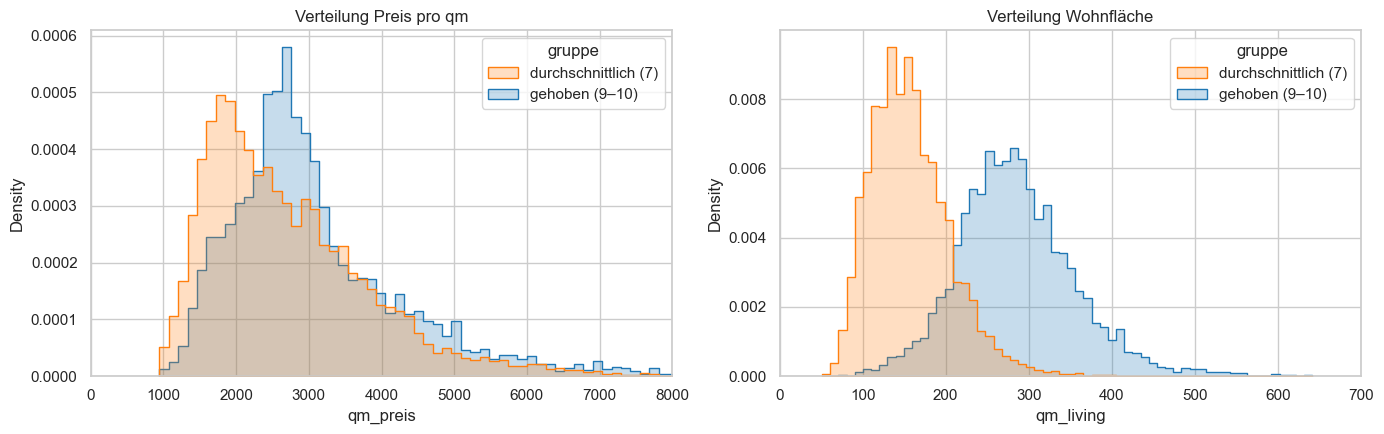

                      qm_preis      price  qm_living  yr_built
gruppe                                                        
durchschnittlich (7)  2,459.02 375,000.00     151.43  1,963.00
gehoben (9–10)        2,784.99 775,000.00     279.64  1,995.00


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
farben = {"durchschnittlich (7)": "tab:orange", "gehoben (9–10)": "tab:blue"}
sns.histplot(data=vergleich, x="qm_preis", hue="gruppe", bins=60, stat="density", common_norm=False,
             element="step", palette=farben, ax=axes[0])
axes[0].set_title("Verteilung Preis pro qm")
axes[0].set_xlim(0, 8000)
sns.histplot(data=vergleich, x="qm_living", hue="gruppe", bins=60, stat="density", common_norm=False,
             element="step", palette=farben, ax=axes[1])
axes[1].set_title("Verteilung Wohnfläche")
axes[1].set_xlim(0, 700)
plt.tight_layout()
plt.show()
print(vergleich.groupby("gruppe")[["qm_preis", "price", "qm_living", "yr_built"]].median())

**Was sehen wir?**
* Beim **qm-Preis** überlappen sich die Gruppen stark.
* Bei der **Wohnfläche** sind sie völlig verschieden: Gehobene Häuser sind im Median fast **doppelt so groß** (~280 qm vs. ~150 qm) und deutlich jünger.
* Ein Gesamtvergleich vergleicht also nicht nur Ausstattung, sondern auch **kleine mit großen Häusern**.

---
## 5 · Zusammenhänge

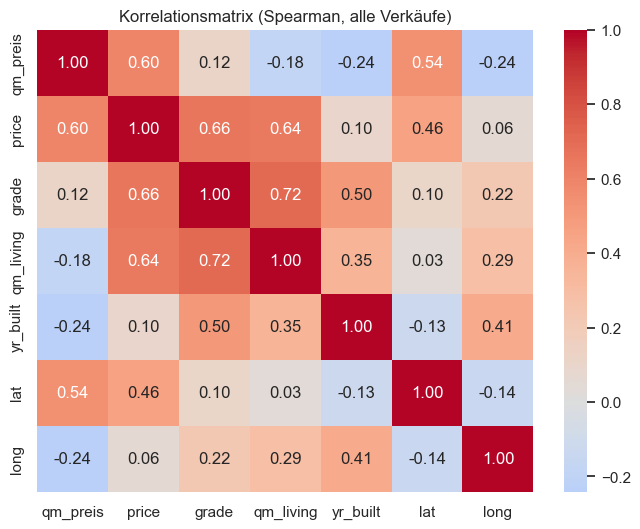

In [16]:
korr = df[["qm_preis", "price", "grade", "qm_living", "yr_built", "lat", "long"]].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(korr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korrelationsmatrix (Spearman, alle Verkäufe)")
plt.show()

**Was sehen wir?** `grade` hängt stark mit dem **Gesamtpreis** zusammen (≈ 0,66), mit dem **qm-Preis** aber viel schwächer. Der Grund: `grade` hängt stark mit der **Wohnfläche** zusammen (≈ 0,72), und größere Häuser sind pro qm eher günstiger. Die Größe verdeckt also den Qualitätseffekt, das zeigt das nächste Diagramm.

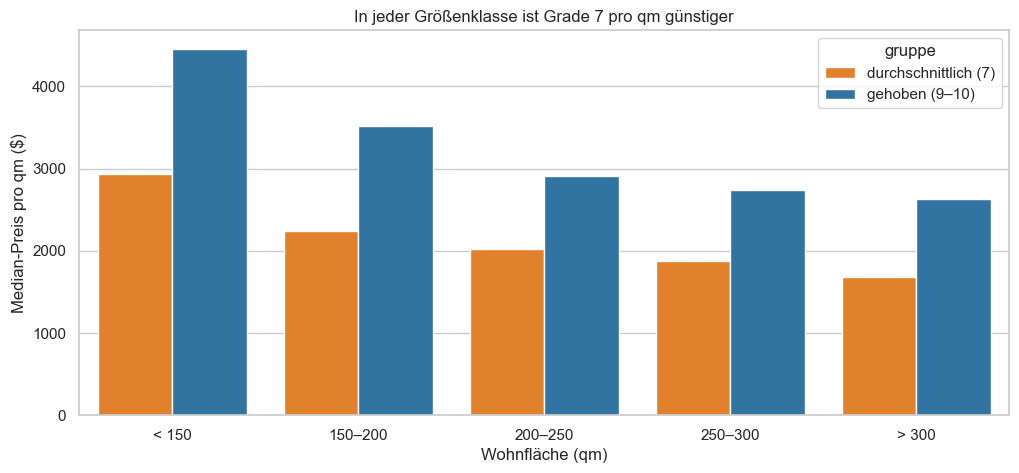

In [17]:
vergleich["groesse"] = pd.cut(vergleich["qm_living"], [0, 150, 200, 250, 300, 2000],
                              labels=["< 150", "150–200", "200–250", "250–300", "> 300"])
plt.figure(figsize=(12, 5))
sns.barplot(data=vergleich, x="groesse", y="qm_preis", hue="gruppe", estimator="median",
            errorbar=None, palette=farben)
plt.title("In jeder Größenklasse ist Grade 7 pro qm günstiger")
plt.xlabel("Wohnfläche (qm)")
plt.ylabel("Median-Preis pro qm ($)")
plt.show()

**Was sehen wir?** Vergleicht man **gleich große** Häuser, ist Grade 7 in **jeder** Größenklasse günstiger pro qm, und zwar deutlich mehr als im Gesamtvergleich. Der faire Vergleich muss also die **Größe** (und die **Lage**) berücksichtigen.

---
## 6 · Hypothese prüfen: Gesamtmarkt
Zuerst die Hypothese wörtlich: alle Grade-7-Verkäufe gegen alle gehobenen Verkäufe.
* **Mann-Whitney-U-Test:** Ist Grade 7 pro qm überhaupt günstiger?
* **Bootstrap (2.000 Ziehungen):** Wie groß ist der Abschlag mit 95 % Sicherheit mindestens?

In [18]:
q7 = vergleich.loc[vergleich["grade"] == 7, "qm_preis"]
qg = vergleich.loc[vergleich["grade"] >= 9, "qm_preis"]
abschlag = 100 * (1 - q7.median() / qg.median())
p_wert = stats.mannwhitneyu(q7, qg, alternative="less").pvalue

rng = np.random.default_rng(42)
boot = np.array([100 * (1 - np.median(rng.choice(q7, len(q7))) / np.median(rng.choice(qg, len(qg))))
                 for _ in range(2000)])
gesichert = np.percentile(boot, 5)

# Wie oft ist ein zufälliges Grade-7-Haus pro qm günstiger als ein zufälliges gehobenes?
anteil_guenstiger = np.mean(rng.choice(q7.values, 100_000) < rng.choice(qg.values, 100_000))

print(f"Median qm-Preis Grade 7:    {q7.median():,.0f} $  (n = {len(q7):,})")
print(f"Median qm-Preis Grade 9–10: {qg.median():,.0f} $  (n = {len(qg):,})")
print(f"Abschlag: {abschlag:.1f} %  | mit 95 % Sicherheit mindestens {gesichert:.1f} %")
print(f"Mann-Whitney p = {p_wert:.1e}")
print(f"In {anteil_guenstiger:.0%} zufälliger Paare ist das Grade-7-Haus pro qm günstiger")
print(f"→ deutlich (≥ 15 %)? {'ja' if gesichert >= 15 else 'nein'}")

Median qm-Preis Grade 7:    2,459 $  (n = 8,974)
Median qm-Preis Grade 9–10: 2,785 $  (n = 3,749)
Abschlag: 11.7 %  | mit 95 % Sicherheit mindestens 10.6 %
Mann-Whitney p = 1.4e-71
In 60% zufälliger Paare ist das Grade-7-Haus pro qm günstiger
→ deutlich (≥ 15 %)? nein


**Ergebnis Gesamtmarkt:**
* Grade 7 ist pro qm **signifikant günstiger**, aber nur um rund **12 %** (gesichert ~11 %).
* In **4 von 10** zufälligen Paaren ist das Grade-7-Haus pro qm sogar **teurer**.
* **→ Am Gesamtmarkt ist der Unterschied nicht deutlich (< 15 %).**

Aber: Wir haben in Schritt 5 gesehen, dass hier kleine mit großen Häusern verglichen werden. Für Thomas' Kaufentscheidung ist ein **fairer Vergleich** wichtiger.

---
## 7 · Folgefrage: fairer Vergleich (gleiche PLZ, gleiche Größe)
Wir vergleichen nur Häuser, die **in derselben Postleitzahl** und **in derselben Größenklasse** liegen. Für jede solche Kombination mit mindestens 5 Häusern pro Gruppe berechnen wir den Abschlag. Dann prüfen wir mit dem **Wilcoxon-Test**, ob die Abschläge systematisch über 0 liegen.

Vergleichbare Kombinationen (PLZ × Größe): 99
Median-Abschlag: 20.6 %  | Grade 7 günstiger in 95% der Fälle
Wilcoxon p = 9.0e-18


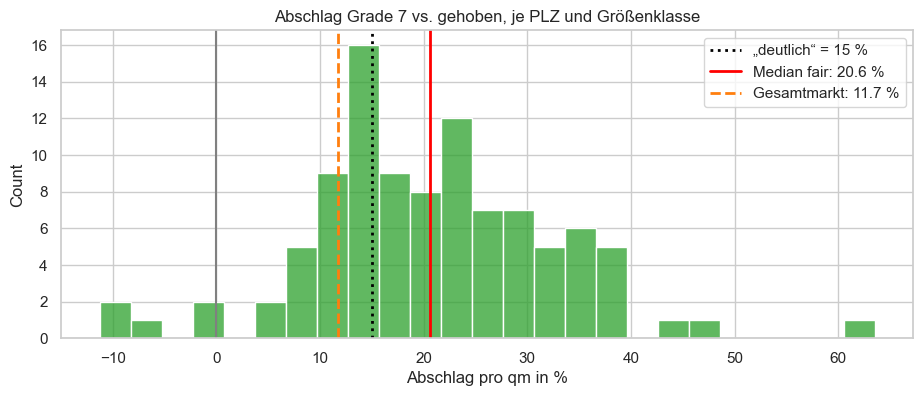

In [19]:
zellen = vergleich.groupby(["zipcode", "groesse", "gruppe"], observed=True)["qm_preis"].agg(["median", "size"]).unstack()
zellen = zellen[(zellen["size"] >= 5).all(axis=1)]
zellen["abschlag"] = 100 * (1 - zellen[("median", "durchschnittlich (7)")] / zellen[("median", "gehoben (9–10)")])

fair = zellen["abschlag"].median()
p_fair = stats.wilcoxon(zellen["abschlag"], alternative="greater").pvalue
print(f"Vergleichbare Kombinationen (PLZ × Größe): {len(zellen)}")
print(f"Median-Abschlag: {fair:.1f} %  | Grade 7 günstiger in {(zellen['abschlag'] > 0).mean():.0%} der Fälle")
print(f"Wilcoxon p = {p_fair:.1e}")

fig, ax = plt.subplots(figsize=(11, 4))
sns.histplot(zellen["abschlag"], bins=25, color="tab:green", ax=ax)
ax.axvline(0, color="gray")
ax.axvline(15, color="black", ls=":", lw=2, label="„deutlich“ = 15 %")
ax.axvline(fair, color="red", lw=2, label=f"Median fair: {fair:.1f} %")
ax.axvline(abschlag, color="tab:orange", lw=2, ls="--", label=f"Gesamtmarkt: {abschlag:.1f} %")
ax.set_title("Abschlag Grade 7 vs. gehoben, je PLZ und Größenklasse")
ax.set_xlabel("Abschlag pro qm in %")
ax.legend()
plt.show()

**Ergebnis fairer Vergleich:** Bei **gleicher Lage und gleicher Größe** ist Grade 7 pro qm im Median rund **20 %** günstiger, und das in **fast allen** Kombinationen. Das liegt klar über der 15-%-Schwelle. **→ Für vergleichbare Häuser ist H3 bestätigt.**

---
## 8 · Fancy Visual: Preisvergleich je Postleitzahl
Für Häuser mit **150–300 qm** (die Größe, in der es beide Gruppen gibt) zeigt jede Zeile eine Postleitzahl: **orange = Grade 7, blau = gehoben**. Je länger die Verbindung, desto mehr spart man dort (interaktiv, auch als HTML in `output/`).

In [20]:
mittel = vergleich[vergleich["qm_living"].between(150, 300)]
plz = mittel.groupby(["zipcode", "gruppe"])["qm_preis"].agg(["median", "size"]).unstack()
plz = plz[(plz["size"] >= 5).all(axis=1)]
plz = pd.DataFrame({"g7": plz[("median", "durchschnittlich (7)")], "geh": plz[("median", "gehoben (9–10)")]})
plz["abschlag"] = 100 * (1 - plz["g7"] / plz["geh"])
plz = plz.sort_values("geh")
namen = "PLZ " + plz.index.astype(str)

fig = go.Figure()
for name, zeile in zip(namen, plz.itertuples()):
    fig.add_trace(go.Scatter(x=[zeile.g7, zeile.geh], y=[name, name], mode="lines",
                             line=dict(color="lightgray", width=4), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter(x=plz["g7"], y=namen, mode="markers", name="durchschnittlich (Grade 7)",
                         marker=dict(size=11, color="#eb6834"), customdata=plz["abschlag"],
                         hovertemplate="%{y}<br>Grade 7: %{x:,.0f} $/qm<br>Abschlag: %{customdata:.0f} %<extra></extra>"))
fig.add_trace(go.Scatter(x=plz["geh"], y=namen, mode="markers", name="gehoben (Grade 9–10)",
                         marker=dict(size=11, color="#2a78d6"),
                         hovertemplate="%{y}<br>gehoben: %{x:,.0f} $/qm<extra></extra>"))
fig.update_layout(
    title=f"In {(plz['abschlag'] > 0).sum()} von {len(plz)} Postleitzahlen ist Grade 7 pro qm günstiger "
          f"(Median-Abschlag {plz['abschlag'].median():.0f} %, Häuser 150–300 qm)",
    xaxis_title="Median-Preis pro qm ($)", height=max(500, 22 * len(plz)), template="plotly_white",
    legend=dict(orientation="h", y=1.02, x=0),
)
fig.write_html("output/h3_easy_plz_vergleich.html")
fig.show()

**Was sehen wir?** In fast jeder Postleitzahl liegt der orange Punkt (Grade 7) **links** vom blauen (gehoben). Gleichzeitig sieht man: Ein Grade-7-Haus in einer teuren PLZ (oben) kostet pro qm mehr als ein gehobenes Haus in einer günstigen PLZ (unten). **Die Lage schlägt die Ausstattung.**

---
## 9 · Erkenntnisse & Empfehlungen

### Ergebnis
| Vergleich | Abschlag Grade 7 vs. gehoben | deutlich (≥ 15 %)? |
|---|---|---|
| Gesamtmarkt (Hypothese wörtlich) | **≈ 12 %**, signifikant | ✗ |
| Fair: gleiche PLZ & gleiche Größe | **≈ 20 %**, in fast allen Fällen | ✓ |
| **Urteil** | **✓ H3 bestätigt für vergleichbare Häuser**, am Gesamtmarkt nur schwach | |

### Erkenntnisse
1. **Am Gesamtmarkt ist der Unterschied klein:** Grade 7 ist pro qm nur ~12 % günstiger, und in 4 von 10 Paaren sogar teurer.
2. **Die Hausgröße verdeckt den Effekt:** Gehobene Häuser sind fast doppelt so groß, und große Häuser sind pro qm günstiger.
3. **Bei gleicher Lage und Größe spart man rund 20 %** pro qm mit durchschnittlicher Bauqualität, das passt gut zum Baukostenunterschied (~17 %).

### Empfehlungen für Thomas
1. **Auf gehobene Ausstattung verzichten:** In derselben Nachbarschaft bekommt er bei gleicher Größe rund **20 % mehr Fläche fürs Geld**. Bei 200 qm sind das grob 100.000 $.
2. **qm-Preise nur innerhalb einer Nachbarschaft vergleichen:** Über Stadtteile hinweg ist „Grade 7 = günstig“ nicht verlässlich, denn die Lage wirkt stärker als die Ausstattung.
3. **Alter mit einrechnen:** Grade-7-Häuser sind im Median deutlich älter. Renovierungs- und Energiekosten einplanen.

### Grenzen
`grade` ist eine Einstufung des Assessors, keine Messung · nur Kombinationen mit genug Häusern beider Gruppen vergleichbar · Markt 2014/15 · keine Kausalaussage.